In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
sample = pd.read_csv("../data/sample_submission.csv")

print("Train (số dòng, số cột):", train.shape)
print("Test (số dòng, số cột):", test.shape)
print("Tệp mẫu (số dòng, số cột):", sample.shape)

print("Cột có ở train nhưng không có ở test:",
      sorted(set(train.columns) - set(test.columns)))
print("Các cột của tệp mẫu:", sample.columns.tolist())

display(train.head())
display(sample.head())

Train (số dòng, số cột): (699960, 26)
Test (số dòng, số cột): (299984, 25)
Tệp mẫu (số dòng, số cột): (299984, 2)
Cột có ở train nhưng không có ở test: ['is_fraud']
Các cột của tệp mẫu: ['id', 'is_fraud']


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


,id,is_fraud
0,699960,0.0167
1,699961,0.0167
2,699962,0.0167
3,699963,0.0167
4,699964,0.0167


In [9]:
print("Kiểu dữ liệu của từng cột:")
print(train.dtypes.to_string())

print("\nTổng ô thiếu trong train:", train.isna().sum().sum())
print("Tổng ô thiếu trong test:", test.isna().sum().sum())

print("\nID bị trùng trong train:", train["id"].duplicated().sum())
print("ID bị trùng trong test:", test["id"].duplicated().sum())
print("ID của tệp mẫu khớp với test:",
      sample["id"].equals(test["id"]))

Kiểu dữ liệu của từng cột:
id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generat

In [10]:
print("Số giao dịch:")
print(train["is_fraud"].value_counts().sort_index())

print("\nTỷ lệ phần trăm:")
print(
    (train["is_fraud"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Số giao dịch:
is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

Tỷ lệ phần trăm:
is_fraud
0.0    98.33
1.0     1.67
Name: proportion, dtype: float64


is_fraud,0.0,1.0
amount_usd,27.21,31.18
account_balance_usd,1382.74,1396.00
hours_since_last_txn,4.73,3.61
txn_count_last_24h,3.00,4.00
distance_from_home_km,10.22,10.31


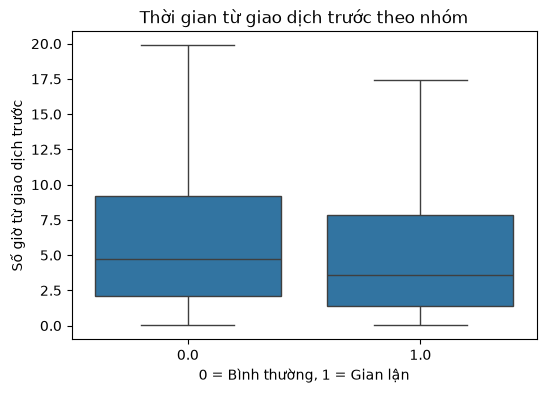

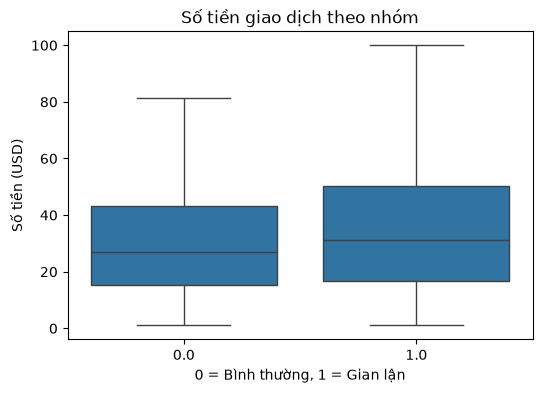

In [11]:
cot_so = [
    "amount_usd",
    "account_balance_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
]

bang_so_sanh = train.groupby("is_fraud")[cot_so].median().round(2).T
display(bang_so_sanh)

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=train,
    x="is_fraud",
    y="hours_since_last_txn",
    showfliers=False
)
plt.title("Thời gian từ giao dịch trước theo nhóm")
plt.xlabel("0 = Bình thường, 1 = Gian lận")
plt.ylabel("Số giờ từ giao dịch trước")
plt.show()

# Lấy 5.000 giao dịch mỗi nhóm để vẽ nhanh hơn
mau_ve = (
    train.groupby("is_fraud", group_keys=False)
    .sample(n=5000, random_state=42)
)

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=mau_ve,
    x="is_fraud",
    y="amount_usd",
    showfliers=False
)
plt.title("Số tiền giao dịch theo nhóm")
plt.xlabel("0 = Bình thường, 1 = Gian lận")
plt.ylabel("Số tiền (USD)")
plt.show()

In [12]:
bang_danh_muc = (
    train.groupby("merchant_category")["is_fraud"]
    .agg(
        so_giao_dich="size",
        so_gian_lan="sum",
        ty_le_gian_lan="mean"
    )
    .sort_values("ty_le_gian_lan", ascending=False)
)

bang_danh_muc["so_gian_lan"] = bang_danh_muc["so_gian_lan"].astype(int)
bang_danh_muc["ty_le_gian_lan"] = (
    bang_danh_muc["ty_le_gian_lan"] * 100
).round(2)

display(bang_danh_muc)

for cot in ["channel", "auth_method", "device_type", "card_type"]:
    bang = train.groupby(cot)["is_fraud"].agg(
        so_giao_dich="size",
        ty_le_gian_lan="mean"
    )
    bang["ty_le_gian_lan"] = (bang["ty_le_gian_lan"] * 100).round(2)

    print("\nCột:", cot)
    display(bang.sort_values("ty_le_gian_lan", ascending=False))

,so_giao_dich,so_gian_lan,ty_le_gian_lan
merchant_category,,,
Gift Cards,9456,690,7.30
Crypto Exchange,5285,345,6.53
Gaming,23784,1311,5.51
Electronics,48693,1501,3.08
Streaming,47196,1061,2.25
Travel,28715,534,1.86
Utilities,42027,581,1.38
Healthcare,35889,462,1.29
Fuel,59880,741,1.24



Cột: channel


,so_giao_dich,ty_le_gian_lan
channel,,
Online,273939,1.74
POS,206465,1.66
In-App,83716,1.63
ATM,30220,1.59
Contactless,105620,1.55



Cột: auth_method


,so_giao_dich,ty_le_gian_lan
auth_method,,
No Authentication,67060,6.44
3D Secure,210036,1.47
OTP,175178,1.41
PIN,154020,0.87
Biometric,93666,0.50



Cột: device_type


,so_giao_dich,ty_le_gian_lan
device_type,,
POS Terminal,113237,1.73
iPhone,164691,1.72
Mac,33973,1.71
ATM Machine,20877,1.70
Tablet,27688,1.70
Smart Watch,21106,1.70
Android Phone,237454,1.61
Windows PC,80934,1.61



Cột: card_type


,so_giao_dich,ty_le_gian_lan
card_type,,
Amex,45797,1.90
Visa,345001,1.70
RuPay,37070,1.68
Mastercard,254857,1.60
Discover,17235,1.46


In [13]:
for cot in ["time_of_day_hour", "day_of_week"]:
    bang_thoi_gian = (
        train.groupby(cot)["is_fraud"]
        .agg(so_giao_dich="size", ty_le_gian_lan="mean")
        .sort_index()
    )
    bang_thoi_gian["ty_le_gian_lan"] = (
        bang_thoi_gian["ty_le_gian_lan"] * 100
    ).round(2)

    print("\nCột:", cot)
    display(bang_thoi_gian)


Cột: time_of_day_hour


,so_giao_dich,ty_le_gian_lan
time_of_day_hour,,
0,25806,1.69
1,29912,1.44
2,26868,1.67
3,26967,1.75
4,27349,1.64
5,27412,1.78
6,27374,1.71
7,29779,1.66
8,27153,1.65



Cột: day_of_week


,so_giao_dich,ty_le_gian_lan
day_of_week,,
0,100548,1.58
1,102288,1.66
2,101467,1.67
3,97261,1.64
4,102508,1.68
5,95271,1.68
6,100617,1.78


In [14]:
# Tương quan giữa từng cột số và is_fraud
train_so = train.select_dtypes(include=["number", "bool"]).drop(columns=["id"])

tuong_quan = train_so.corr()["is_fraud"].drop("is_fraud")
tuong_quan = tuong_quan.reindex(
    tuong_quan.abs().sort_values(ascending=False).index
)

print("Các cột có tương quan mạnh nhất với is_fraud:")
display(tuong_quan.head(15).round(3))

# Tương quan giữa các cột đầu vào
corr_giua_cac_cot = train_so.drop(columns="is_fraud").corr().abs()
cap_cot = corr_giua_cac_cot.unstack()
cap_cot = cap_cot[
    cap_cot.index.get_level_values(0) < cap_cot.index.get_level_values(1)
]

print("10 cặp cột có tương quan cao nhất:")
display(cap_cot.sort_values(ascending=False).head(10).round(3))

# Phần xu của số tiền: 0 đến 99
phan_xu = ((train["amount_usd"] * 100).round().astype(int) % 100)

bang_phan_xu = (
    train.assign(phan_xu=phan_xu)
    .groupby("phan_xu")["is_fraud"]
    .agg(so_giao_dich="size", ty_le_gian_lan="mean")
)
bang_phan_xu["ty_le_gian_lan"] = (
    bang_phan_xu["ty_le_gian_lan"] * 100
).round(2)

print("15 phần xu xuất hiện nhiều nhất:")
display(bang_phan_xu.sort_values("so_giao_dich", ascending=False).head(15))

# So sánh số tiền tròn đô la với số tiền có phần xu
bang_so_tien_tron = (
    train.assign(so_tien_tron=phan_xu.eq(0))
    .groupby("so_tien_tron")["is_fraud"]
    .agg(so_giao_dich="size", ty_le_gian_lan="mean")
)
bang_so_tien_tron["ty_le_gian_lan"] = (
    bang_so_tien_tron["ty_le_gian_lan"] * 100
).round(2)

print("Số tiền tròn đô la (True) và không tròn (False):")
display(bang_so_tien_tron)

Các cột có tương quan mạnh nhất với is_fraud:


cvv_retry_count                 0.212
ip_country_mismatch             0.148
merchant_risk_score             0.125
is_foreign_transaction          0.113
velocity_score                  0.102
is_new_merchant                 0.101
billing_shipping_mismatch       0.101
used_vpn                        0.071
is_ai_generated_scam_attempt    0.061
txn_count_last_24h              0.058
customer_age                    0.056
prior_disputes                  0.024
hours_since_last_txn           -0.020
amount_usd                      0.019
day_of_week                     0.004
Name: is_fraud, dtype: float64

10 cặp cột có tương quan cao nhất:


txn_count_last_24h         velocity_score            0.621
hours_since_last_txn       velocity_score            0.344
ip_country_mismatch        is_foreign_transaction    0.290
amount_usd                 merchant_risk_score       0.169
hours_since_last_txn       txn_count_last_24h        0.038
cvv_retry_count            ip_country_mismatch       0.032
                           merchant_risk_score       0.027
billing_shipping_mismatch  cvv_retry_count           0.024
merchant_risk_score        velocity_score            0.023
cvv_retry_count            is_new_merchant           0.023
dtype: float64

15 phần xu xuất hiện nhiều nhất:


,so_giao_dich,ty_le_gian_lan
phan_xu,,
21,11203,1.32
47,10213,1.41
19,10119,1.42
11,9931,1.46
94,9885,1.42
29,9779,1.51
18,9710,1.29
37,9619,1.51
6,9445,1.75


Số tiền tròn đô la (True) và không tròn (False):


,so_giao_dich,ty_le_gian_lan
so_tien_tron,,
False,693401,1.67
True,6559,2.09


## Kết luận phân tích dữ liệu (EDA)

- Tập train có 699.960 giao dịch và 26 cột; tập test có 299.984 giao dịch và 25 cột. `is_fraud` là cột cần dự đoán, chỉ có trong train.
- Train và test không có giá trị thiếu. ID không bị trùng; ID trong `sample_submission.csv` khớp với test.
- Có 11.689 giao dịch gian lận (1,67%) và 688.271 giao dịch bình thường (98,33%). Hai lớp rất mất cân bằng.
- Nhóm gian lận có trung vị số tiền cao hơn (31,18 USD so với 27,21 USD), thời gian từ giao dịch trước ngắn hơn (3,61 giờ so với 4,73 giờ) và nhiều giao dịch hơn trong 24 giờ gần nhất (4 so với 3). Phân bố hai nhóm vẫn chồng lấn nhiều.
- Gift Cards (7,30%), Crypto Exchange (6,53%) và Gaming (5,51%) có tỷ lệ gian lận cao hơn mức chung. Nhóm No Authentication có tỷ lệ gian lận 6,44%.
- Tỷ lệ gian lận theo giờ và ngày trong tuần chỉ thay đổi nhẹ. Trong các cột số, `cvv_retry_count` có tương quan với `is_fraud` cao nhất (0,212).
- Giao dịch tròn đô la có tỷ lệ gian lận 2,09%, so với 1,67% ở các giao dịch còn lại. Nhóm có thể thử đặc trưng này khi xây mô hình.
- Các kết quả trên mô tả mối liên hệ trong dữ liệu, chưa chứng minh quan hệ nguyên nhân. Cần kiểm tra hiệu quả đặc trưng bằng validation.

In [15]:
cot_so = [
    c for c in train.select_dtypes(include="number").columns
    if c not in ["id", "is_fraud"]
]

bang_so_sanh = pd.DataFrame({
    "train_trung_vi": train[cot_so].median(),
    "test_trung_vi": test[cot_so].median(),
    "train_moc_90": train[cot_so].quantile(0.90),
    "test_moc_90": test[cot_so].quantile(0.90),
}).round(2)

display(bang_so_sanh)

,train_trung_vi,test_trung_vi,train_moc_90,test_moc_90
amount_usd,27.25,27.28,89.80,92.13
hours_since_last_txn,4.73,4.72,14.99,15.02
txn_count_last_24h,3.00,3.00,5.00,5.00
distance_from_home_km,10.22,10.27,31.43,31.43
card_age_months,47.00,47.00,54.00,54.00
customer_age,52.00,52.00,76.00,76.00
account_balance_usd,1382.74,1388.54,4026.02,4031.64
cvv_retry_count,0.00,0.00,0.00,0.00
velocity_score,18.60,18.70,33.10,33.10
time_of_day_hour,12.00,12.00,21.00,21.00


In [16]:
cot_nhom = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
]

for cot in cot_nhom:
    ty_le_train = train[cot].value_counts(normalize=True) * 100
    ty_le_test = test[cot].value_counts(normalize=True) * 100

    bang = pd.DataFrame({
        "train_%": ty_le_train,
        "test_%": ty_le_test,
    }).fillna(0).round(2)

    bang["chenh_lech_diem_%"] = (bang["test_%"] - bang["train_%"]).round(2)

    print("Cột:", cot)
    display(bang.sort_values("train_%", ascending=False))

Cột: merchant_category


,train_%,test_%,chenh_lech_diem_%
merchant_category,,,
Online Retail,22.16,22.20,0.04
Groceries,20.37,20.45,0.08
Restaurants,14.48,14.38,-0.10
Fuel,8.55,8.62,0.07
Electronics,6.96,6.96,0.00
Streaming,6.74,6.65,-0.09
Utilities,6.00,5.98,-0.02
Healthcare,5.13,5.15,0.02
Travel,4.10,4.09,-0.01


Cột: card_type


,train_%,test_%,chenh_lech_diem_%
card_type,,,
Visa,49.29,49.38,0.09
Mastercard,36.41,36.36,-0.05
Amex,6.54,6.51,-0.03
RuPay,5.30,5.26,-0.04
Discover,2.46,2.49,0.03


Cột: auth_method


,train_%,test_%,chenh_lech_diem_%
auth_method,,,
3D Secure,30.01,30.02,0.01
OTP,25.03,25.17,0.14
PIN,22.00,22.06,0.06
Biometric,13.38,13.41,0.03
No Authentication,9.58,9.35,-0.23


Cột: channel


,train_%,test_%,chenh_lech_diem_%
channel,,,
Online,39.14,39.02,-0.12
POS,29.50,29.58,0.08
Contactless,15.09,15.22,0.13
In-App,11.96,11.87,-0.09
ATM,4.32,4.31,-0.01


Cột: device_type


,train_%,test_%,chenh_lech_diem_%
device_type,,,
Android Phone,33.92,33.83,-0.09
iPhone,23.53,23.48,-0.05
POS Terminal,16.18,16.23,0.05
Windows PC,11.56,11.56,0.00
Mac,4.85,4.87,0.02
Tablet,3.96,3.97,0.01
Smart Watch,3.02,3.07,0.05
ATM Machine,2.98,3.00,0.02


In [17]:
cot_bool = [
    c for c in train.select_dtypes(include="bool").columns
    if c in test.columns
]

bang_bool = pd.DataFrame({
    "train_%_True": train[cot_bool].mean() * 100,
    "test_%_True": test[cot_bool].mean() * 100,
}).round(2)

bang_bool["chenh_lech_diem_%"] = (
    bang_bool["test_%_True"] - bang_bool["train_%_True"]
).round(2)

display(bang_bool)

,train_%_True,test_%_True,chenh_lech_diem_%
is_foreign_transaction,1.73,1.74,0.01
is_new_merchant,15.25,15.28,0.03
used_vpn,3.38,3.30,-0.08
ip_country_mismatch,1.62,1.60,-0.02
billing_shipping_mismatch,1.29,1.31,0.02
is_ai_generated_scam_attempt,0.33,0.34,0.01


Phân phối các đặc trưng số, phân loại và True/False giữa train và test nhìn chung tương tự nhau. Trong các nhóm đã kiểm tra, chênh lệch tỷ lệ lớn nhất là No Authentication (0,23 điểm phần trăm); các cột True/False chênh lệch tối đa 0,08 điểm phần trăm. Chưa thấy dấu hiệu lệch phân phối lớn khi xét từng cột riêng lẻ. Tuy nhiên, test không có nhãn is_fraud, nên chưa thể so sánh tỷ lệ gian lận giữa hai tập hoặc khẳng định mô hình sẽ hoạt động tốt trên test.

In [18]:
gia_tri_so_nghi_ngo = [-1, -999, 9999]
gia_tri_chu_nghi_ngo = {"unknown", "missing", "n/a", "na", "none", ""}

ket_qua = []

for ten_tap, df in [("train", train), ("test", test)]:
    cot_so = [
        c for c in df.select_dtypes(include="number").columns
        if c not in ["id", "is_fraud"]
    ]

    for cot in cot_so:
        for gia_tri in gia_tri_so_nghi_ngo:
            so_luong = int(df[cot].eq(gia_tri).sum())
            if so_luong > 0:
                ket_qua.append([ten_tap, cot, gia_tri, so_luong])

    for cot in df.select_dtypes(include="object").columns:
        gia_tri_chuan_hoa = df[cot].astype("string").str.strip().str.lower()
        for gia_tri in gia_tri_chu_nghi_ngo:
            so_luong = int(gia_tri_chuan_hoa.eq(gia_tri).sum())
            if so_luong > 0:
                ket_qua.append([ten_tap, cot, repr(gia_tri), so_luong])

if ket_qua:
    display(pd.DataFrame(
        ket_qua,
        columns=["tap_du_lieu", "cot", "gia_tri_nghi_ngo", "so_luong"]
    ))
else:
    print("Không tìm thấy các giá trị nghi ngờ đã kiểm tra.")

C:\Users\Admin\AppData\Local\Temp\ipykernel_174764\2206837849.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for cot in df.select_dtypes(include="object").columns:
C:\Users\Admin\AppData\Local\Temp\ipykernel_174764\2206837849.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guid

Không tìm thấy các giá trị nghi ngờ đã kiểm tra.


Train và test không có giá trị thiếu dạng NaN. Kiểm tra thêm một số giá trị thường dùng để thay thế dữ liệu thiếu (-1, -999, 9999, Unknown, Missing, N/A) cũng không phát hiện trường hợp nào. Chưa thể khẳng định dữ liệu không có các quy ước thay thế khác.

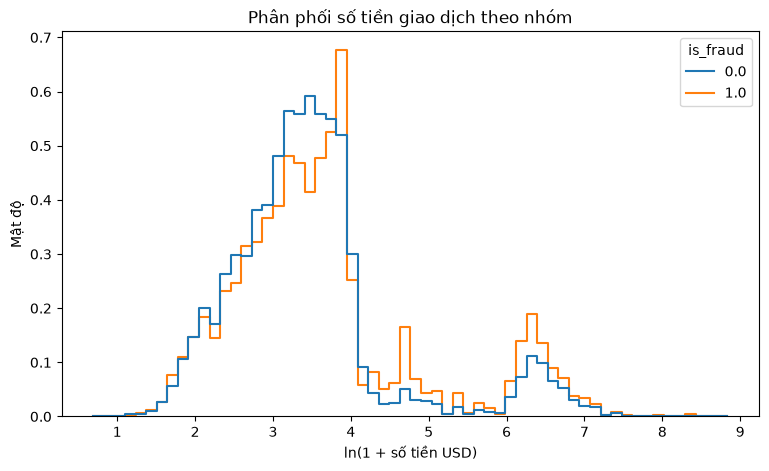

In [19]:
import numpy as np

du_lieu_ve = train[["amount_usd", "is_fraud"]].copy()
du_lieu_ve["log_amount"] = np.log1p(du_lieu_ve["amount_usd"])

plt.figure(figsize=(9, 5))
sns.histplot(
    data=du_lieu_ve,
    x="log_amount",
    hue="is_fraud",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)

plt.title("Phân phối số tiền giao dịch theo nhóm")
plt.xlabel("ln(1 + số tiền USD)")
plt.ylabel("Mật độ")
plt.show()

Phân phối amount_usd trên thang ln(1 + amount_usd) cho thấy cả giao dịch bình thường và gian lận đều có phần lớn giá trị ở vùng số tiền thấp, cùng một cụm ở vùng số tiền cao hơn. Hai phân phối chồng lấn đáng kể; số tiền có thể mang tín hiệu nhưng không đủ để kết luận một giao dịch là gian lận.

In [20]:
bang_ket_hop = (
    train.groupby(["merchant_category", "auth_method"])["is_fraud"]
    .agg(so_giao_dich="size", so_gian_lan="sum", ty_le_gian_lan="mean")
    .reset_index()
)

bang_ket_hop["ty_le_gian_lan_%"] = (
    bang_ket_hop["ty_le_gian_lan"] * 100
).round(2)

print("Tỷ lệ gian lận chung (%):", round(train["is_fraud"].mean() * 100, 2))

display(
    bang_ket_hop.loc[bang_ket_hop["so_giao_dich"] >= 1000]
    .sort_values("ty_le_gian_lan_%", ascending=False)
    .head(15)[
        ["merchant_category", "auth_method",
         "so_giao_dich", "so_gian_lan", "ty_le_gian_lan_%"]
    ]
)

Tỷ lệ gian lận chung (%): 1.67


,merchant_category,auth_method,so_giao_dich,so_gian_lan,ty_le_gian_lan_%
22,Gift Cards,No Authentication,1104,254.0,23.01
17,Gaming,No Authentication,2629,502.0,19.09
7,Electronics,No Authentication,4543,515.0,11.34
47,Streaming,No Authentication,4744,412.0,8.68
52,Travel,No Authentication,2584,193.0,7.47
0,Crypto Exchange,3D Secure,1599,114.0,7.13
20,Gift Cards,3D Secure,2793,193.0,6.91
23,Gift Cards,OTP,2332,130.0,5.57
3,Crypto Exchange,OTP,1219,66.0,5.41
57,Utilities,No Authentication,4086,220.0,5.38


Một số tổ hợp merchant_category và auth_method có tỷ lệ gian lận cao hơn đáng kể mức chung 1,67%, nổi bật là Gift Cards + No Authentication (23,01%) và Gaming + No Authentication (19,09%). Đây là mối liên hệ quan sát được trong train; cần kiểm tra bằng validation trước khi kết luận tổ hợp này giúp mô hình dự đoán tốt hơn.

In [21]:
cot_dac_trung = [c for c in test.columns if c != "id"]

ma_train = pd.util.hash_pandas_object(train[cot_dac_trung], index=False)
ma_test = pd.util.hash_pandas_object(test[cot_dac_trung], index=False)

print("Số hàng trùng toàn bộ đặc trưng trong train:",
      ma_train.duplicated().sum())
print("Số hàng trùng toàn bộ đặc trưng trong test:",
      ma_test.duplicated().sum())
print("Số hàng test trùng toàn bộ đặc trưng với train:",
      ma_test.isin(set(ma_train)).sum())

Số hàng trùng toàn bộ đặc trưng trong train: 0
Số hàng trùng toàn bộ đặc trưng trong test: 0
Số hàng test trùng toàn bộ đặc trưng với train: 0


Không phát hiện bản ghi trùng toàn bộ đặc trưng trong train, trong test hoặc giữa hai tập. Dữ liệu không có user_id, card_id hay mã thiết bị riêng, nên chưa thể kiểm tra liệu giao dịch của cùng một thực thể có xuất hiện ở cả train và validation hay không. device_type chỉ là loại thiết bị, không phải mã định danh thiết bị.